In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sentinelhub import SHConfig
import getpass
import utils
import cdsapi

In [2]:
config = SHConfig()
config.sh_client_id = getpass.getpass("Enter your SentinelHub client id")
config.sh_client_secret = getpass.getpass("Enter your SentinelHub client secret")
config.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
config.sh_base_url = "https://sh.dataspace.copernicus.eu"
config.save("cdse")

In [9]:
# sh-1a85fd10-3727-4990-8d09-a0d91739554a
# sYXOmMPQKPyB8CmRlmfg80z8vGQmYBlji9zC0iYWLIQHfu5hIIJnbgHlmhJAxIoWLLem2h1iK3Em65GtOfojcz

In [3]:
# coordinates for Empordà with irrigated crops (rice), dry farmlands (cereals), forest and scrub
bbox_coords = [2.97, 41.92, 3.19, 42.10]
resolution = 20
dates = [['2023', '07']]
# dates = ("2023-07-01", "2023-07-31")

df = utils.get_ndmi(bbox_coords, resolution, dates, config)


In [4]:
df_date = df[df['time'] == '2023-07-01'].drop(columns = ['time'])
ndmi_mat = df_date.ndmi_median.to_numpy()
ndmi_mat = ndmi_mat.reshape((df.lat.nunique(), df.lon.nunique()))

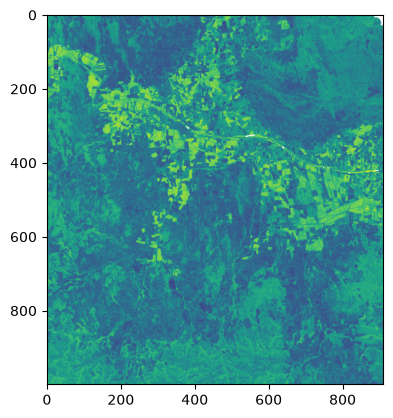

In [5]:
plt.imshow(ndmi_mat)

In [6]:
bbox_coords = [2.97, 41.92, 3.19, 42.10]   # Baix Empordà
resolution = 20

months = [[d.year, d.month] for d in pd.date_range("2017-04", "2025-12", freq="MS")]
utils.get_ndmi(bbox_coords, resolution, months, config, return_data=False)
# ds, df = utils.get_era5(bbox_coords, months, variables)

    

In [8]:
era5_variables = [
    "total_precipitation",
    "2m_temperature",
    "potential_evaporation",
    "total_evaporation",
    "volumetric_soil_water_layer_1",
    "volumetric_soil_water_layer_2",
]

months = [[d.year, d.month] for d in pd.date_range("2017-04", "2025-12", freq="MS")]
df = utils.get_era5(bbox_coords, months, era5_variables)


2026-10-15 13:31:39,064 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-15 13:31:39,266 INFO Request ID is 47c00bf5-7fd4-47ca-8f68-6d492a696254
2026-10-15 13:31:39,766 INFO status has been updated to successful


13aa89bfdd70906aa8781bc266164dba.nc:   0%|          | 0.00/101k [00:00<?, ?B/s]

In [10]:
df.head(40)

,time,lat,lon,tp,t2m,pev,e,swvl1,swvl2
0,2017-04-01,42.2,2.9,0.001407,287.099792,-0.004936,-0.002989,0.246490,0.293152
1,2017-04-01,42.2,3.0,0.001098,287.466980,-0.006402,-0.003045,0.237015,0.273666
2,2017-04-01,42.2,3.1,0.001026,287.552917,-0.007112,-0.003164,0.245377,0.266525
3,2017-04-01,42.2,3.2,NaN,NaN,NaN,NaN,NaN,NaN
4,2017-04-01,42.1,2.9,0.001168,287.259949,-0.005966,-0.002860,0.286789,0.350128
5,2017-04-01,42.1,3.0,0.000992,287.373230,-0.006222,-0.002671,0.257553,0.342667
6,2017-04-01,42.1,3.1,0.000902,287.554871,-0.006417,-0.002869,0.252716,0.343613
7,2017-04-01,42.1,3.2,NaN,NaN,NaN,NaN,NaN,NaN
8,2017-04-01,42.0,2.9,0.000944,287.201355,-0.008114,-0.002738,0.347076,0.388550
9,2017-04-01,42.0,3.0,0.000884,286.961121,-0.008289,-0.002561,0.330521,0.385712
